# Chapitre 1 - Cours 1 : systèmes opérationnels et systèmes analytiques

Le chapitre 1 ouvre le livre sur une idée simple : en architecture de données, il n'y
a pas de bonne réponse universelle, seulement des **compromis**. Le premier, et le plus
structurant pour la suite, sépare les systèmes qui **servent les utilisateurs** (on y lit
et on y modifie quelques enregistrements à la fois) de ceux qui **analysent** l'activité
(on y parcourt des millions d'enregistrements pour en tirer des agrégats). Ce notebook
couvre l'introduction du chapitre, l'encadré *Terminology: Frontends and Backends*, la
section *Operational Versus Analytical Systems* et sa sous-section *Characterizing
Transaction Processing and Analytics*.

**Plan.**

1. Frontend, backend et infrastructure de données : pourquoi le code applicatif est
   sans état.
2. Qui utilise les données ? Les deux familles de systèmes et les métiers qui les relient.
3. Caractériser OLTP et OLAP : mesure du travail de requêtes ponctuelles et analytiques
   sur une base de ventes SQLite.
4. Pourquoi ne pas lancer l'analytique sur la base opérationnelle : simulation de
   l'interférence.
5. Requêtes figées ou ad hoc, analytique en temps réel : le compromis fraîcheur contre
   efficacité.

In [1]:
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

## 1. Frontend, backend et infrastructure de données (encadré *Terminology: Frontends and Backends*)

**Le vocabulaire.** Dans une application web, le code qui s'exécute dans le navigateur
est le **frontend** ; le code côté serveur qui traite les requêtes est le **backend**.
Une application mobile joue le même rôle qu'un frontend. La difficulté se concentre
presque toujours côté backend : un frontend ne gère que les données d'un utilisateur,
alors que le backend gère celles de **tous** les utilisateurs à la fois.

Un service backend est typiquement joignable en HTTP. Il est fait de **code applicatif**
qui lit et écrit dans une ou plusieurs bases de données, et parfois dans d'autres
systèmes (caches, files de messages) : c'est ce que le livre appelle l'**infrastructure
de données**. Point essentiel : le code applicatif est en général **sans état**
(« stateless ») : une fois une requête traitée, il l'oublie. Tout ce qui doit survivre
d'une requête à l'autre vit chez le client ou dans l'infrastructure de données.

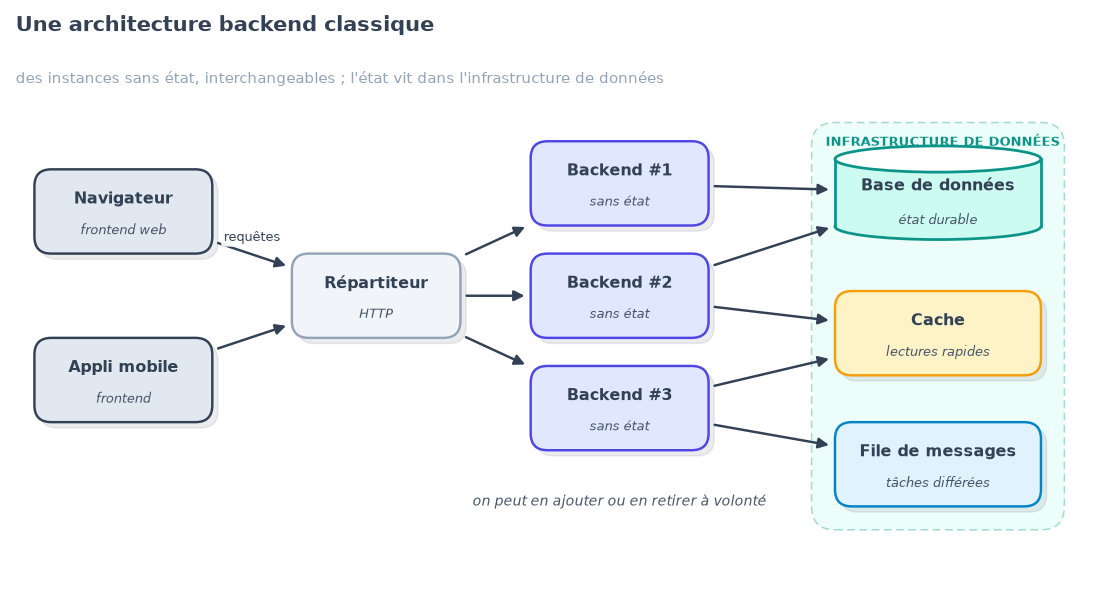

In [2]:
d = Diagram(11.5, 5.2, title="Une architecture backend classique",
            subtitle="des instances sans état, interchangeables ; l'état vit dans l'infrastructure de données")
d.box("web", 1.2, 4.0, "Navigateur", sub="frontend web", color=SLATE, w=1.9)
d.box("mob", 1.2, 2.2, "Appli mobile", sub="frontend", color=SLATE, w=1.9)
d.box("lb", 3.9, 3.1, "Répartiteur", sub="HTTP", color=GRAY, w=1.8)
d.box("b1", 6.5, 4.3, "Backend #1", sub="sans état", color=INDIGO, w=1.9)
d.box("b2", 6.5, 3.1, "Backend #2", sub="sans état", color=INDIGO, w=1.9)
d.box("b3", 6.5, 1.9, "Backend #3", sub="sans état", color=INDIGO, w=1.9)
d.box("db", 9.9, 4.2, "Base de données", sub="état durable", color=TEAL, kind="db", w=2.2, h=1.0)
d.box("cache", 9.9, 2.7, "Cache", sub="lectures rapides", color=AMBER, w=2.2)
d.box("mq", 9.9, 1.3, "File de messages", sub="tâches différées", color=SKY, w=2.2)
d.group(8.55, 0.6, 11.25, 4.95, "infrastructure de données", color=TEAL)
d.arrow("web", "lb", "requêtes")
d.arrow("mob", "lb")
for b in ("b1", "b2", "b3"):
    d.arrow("lb", b)
d.arrow("b1", "db")
d.arrow("b2", "db")
d.arrow("b2", "cache")
d.arrow("b3", "cache")
d.arrow("b3", "mq")
d.note(6.5, 0.9, "on peut en ajouter ou en retirer à volonté")
d.show()

**Pourquoi « sans état » ?** Parce que le répartiteur peut envoyer deux requêtes
successives d'un même utilisateur à deux instances différentes. Démontrons-le : un
panier d'achat est incrémenté six fois, en répartition circulaire (« round robin ») sur
trois instances. Dans la première version, chaque instance garde le panier **dans sa
mémoire** ; dans la seconde, elle le lit et l'écrit dans un stockage partagé (ici un
dictionnaire qui joue le rôle de la base).

In [3]:
class Backend:
    def __init__(self, name, shared):
        self.name, self.local, self.shared = name, {}, shared

    def add_item_local(self, user):        # état dans le processus : à éviter
        self.local[user] = self.local.get(user, 0) + 1
        return self.local[user]

    def add_item_shared(self, user):       # état dans l'infrastructure de données
        self.shared[user] = self.shared.get(user, 0) + 1
        return self.shared[user]


shared_store = {}
instances = [Backend(f"#{i + 1}", shared_store) for i in range(3)]
rows = []
for k in range(6):
    inst = instances[k % 3]                # répartition circulaire
    rows.append({"requête": k + 1, "instance": inst.name,
                 "panier vu (état local)": inst.add_item_local("alice"),
                 "panier vu (état partagé)": inst.add_item_shared("alice")})
pd.DataFrame(rows).set_index("requête")

,instance,panier vu (état local),panier vu (état partagé)
requête,,,
1,#1,1,1
2,#2,1,2
3,#3,1,3
4,#1,2,4
5,#2,2,5
6,#3,2,6


Avec l'état local, Alice voit son panier osciller entre 1 et 2 articles alors qu'elle en
a ajouté six ; et si l'instance #2 redémarre, une partie de son panier disparaît. Avec
l'état partagé, toutes les instances voient le même panier, et n'importe laquelle peut
tomber en panne ou être remplacée sans perte. C'est ce qui rend les instances
**interchangeables**, donc faciles à multiplier (chapitre 2) : la
difficulté est reportée sur l'infrastructure de données, qui est précisément le sujet du
livre.

> **À retenir.** Le frontend gère les données d'un utilisateur, le backend celles de tous.
> Le code applicatif est sans état ; l'état durable (et toute la difficulté : pannes,
> concurrence, volume) vit dans l'infrastructure de données.

## 2. Qui utilise les données ? (section *Operational Versus Analytical Systems*)

Dans une organisation, trois populations travaillent avec les mêmes données :

- les **ingénieurs backend**, qui construisent les services lisant et modifiant les
  données au fil des actions des utilisateurs ;
- les **analystes métier** (« business analysts »), qui produisent des rapports pour aider
  la direction à décider (*business intelligence*, BI) ;
- les **data scientists**, qui cherchent des enseignements nouveaux dans les données ou
  construisent des fonctionnalités fondées sur l'analyse et l'apprentissage automatique
  (recommandations, score de risque, détection de spam, classement de résultats).

Les deux dernières font de l'**analytique** : elles lisent les données produites par les
utilisateurs et les services, sans les modifier (sauf pour corriger des erreurs), et
produisent éventuellement des **jeux de données dérivés**. D'où la distinction qui
traverse tout le livre :

- un **système opérationnel** : services backend et infrastructure où les données sont
  **créées**, lues et modifiées au gré des actions des utilisateurs ;
- un **système analytique** : une **copie en lecture seule** des données opérationnelles,
  organisée pour les traitements dont ont besoin analystes et data scientists.

Deux métiers se sont spécialisés à la frontière : l'**ingénieur de données** (« data
engineer ») intègre les systèmes opérationnels et analytiques et répond de
l'infrastructure de données en général ; l'**ingénieur analytique** (« analytics
engineer ») modélise et transforme les données pour qu'elles servent mieux les analystes.

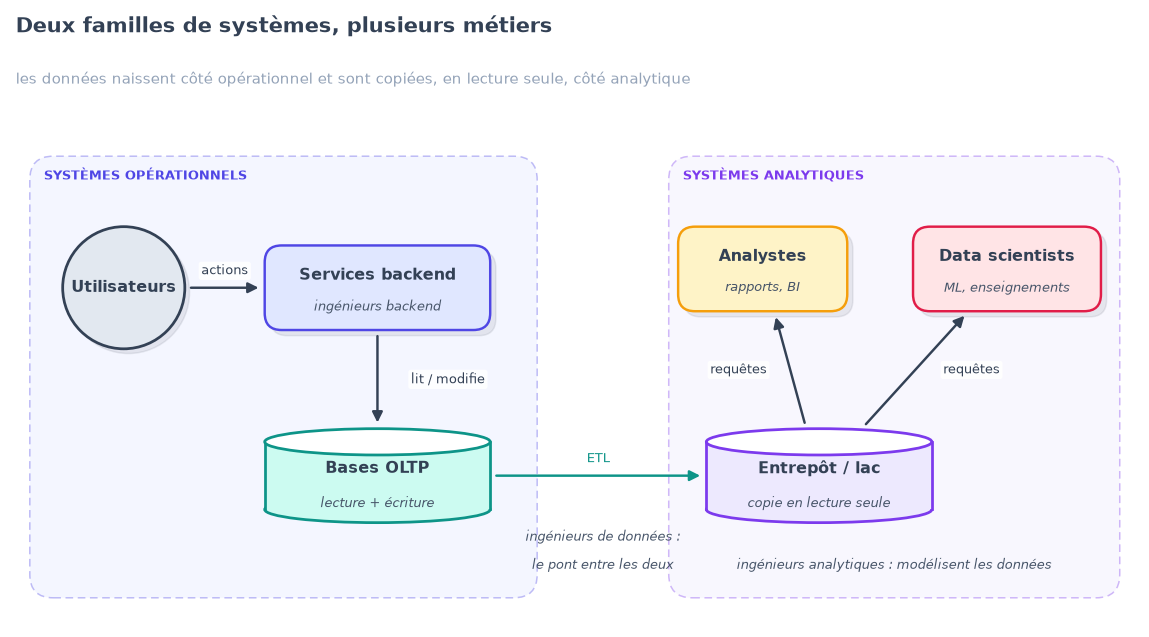

In [4]:
d = Diagram(12, 5.6, title="Deux familles de systèmes, plusieurs métiers",
            subtitle="les données naissent côté opérationnel et sont copiées, en lecture seule, côté analytique")
d.group(0.2, 0.3, 5.6, 5.0, "systèmes opérationnels", color=INDIGO)
d.group(7.0, 0.3, 11.8, 5.0, "systèmes analytiques", color=VIOLET)
d.box("u", 1.2, 3.6, "Utilisateurs", kind="user", w=1.3, color=SLATE)
d.box("svc", 3.9, 3.6, "Services backend", sub="ingénieurs backend", color=INDIGO, w=2.4)
d.box("oltp", 3.9, 1.6, "Bases OLTP", sub="lecture + écriture", color=TEAL, kind="db", w=2.4, h=1.0)
d.box("dw", 8.6, 1.6, "Entrepôt / lac", sub="copie en lecture seule", color=VIOLET, kind="db", w=2.4, h=1.0)
d.box("ba", 8.0, 3.8, "Analystes", sub="rapports, BI", color=AMBER, w=1.8)
d.box("ds", 10.6, 3.8, "Data scientists", sub="ML, enseignements", color=ROSE, w=2.0)
d.arrow("u", "svc", "actions")
d.arrow("svc", "oltp", "lit / modifie", label_offset=(0.75, 0))
d.arrow("oltp", "dw", "ETL", color=TEAL)
d.arrow("dw", "ba", "requêtes", label_offset=(-0.55, 0))
d.arrow("dw", "ds", "requêtes", label_offset=(0.6, 0))
d.note(6.3, 0.95, "ingénieurs de données :", fontsize=8.5)
d.note(6.3, 0.65, "le pont entre les deux", fontsize=8.5)
d.note(9.4, 0.65, "ingénieurs analytiques : modélisent les données", fontsize=8.5)
d.show()

> **À retenir.** Système **opérationnel** : là où les données naissent et changent, au
> service des utilisateurs. Système **analytique** : une copie en lecture seule,
> organisée pour l'analyse. Le livre couvre les deux, car une donnée traverse les deux au
> cours de sa vie.

## 3. Caractériser OLTP et OLAP (section *Characterizing Transaction Processing and Analytics*)

**D'où viennent les mots.** Aux débuts de l'informatique de gestion, une écriture en base
correspondait à une transaction commerciale : une vente, une commande, une paie. Le mot
**transaction** est resté, au sens d'un groupe de lectures et d'écritures formant une
unité logique (le chapitre 8 le précise ; ici, on l'emploie au sens
large d'« accès à faible latence »). Le motif d'accès typique d'un système opérationnel
est la **requête ponctuelle** (« point query ») : retrouver quelques enregistrements par
leur clé, en insérer, en modifier. Comme ces applications sont interactives, on parle
d'**OLTP** (*online transaction processing*).

L'analytique a un tout autre motif : une requête **parcourt un grand nombre
d'enregistrements** pour calculer des agrégats (comptes, sommes, moyennes) plutôt que de
renvoyer des enregistrements individuels. Pour la distinguer, on a parlé d'**OLAP**
(*online analytical processing*).

**Expérience.** Construisons une base de ventes de supermarché (fonction
`ar.make_shop_db` : 2 000 clients, 400 produits, 20 magasins, 150 000 lignes de vente sur
90 jours, popularité des produits en loi de Zipf) et comparons trois requêtes de chaque
famille. Pour mesurer le **travail** de façon déterministe, on compte les instructions
exécutées par la machine virtuelle de SQLite (fonction `ar.vm_steps`, qui s'appuie sur
le « progress handler » de SQLite) ; on mesure aussi le temps.

In [5]:
con = sqlite3.connect(":memory:")
ar.make_shop_db(con, n_customers=2000, n_products=400, n_stores=20, n_sales=150_000, n_days=90, seed=0)

QUERIES = {
    # --- OLTP : quelques lignes, trouvées par une clé
    "OLTP : une vente par son id": ("SELECT * FROM sales WHERE id = ?", (12345,)),
    "OLTP : achats récents d'un client": (
        "SELECT * FROM sales WHERE customer_id = ? ORDER BY day DESC LIMIT 10", (42,)),
    "OLTP : modifier une quantité": ("UPDATE sales SET qty = qty + 1 WHERE id = ?", (777,)),
    # --- OLAP : des agrégats sur une grande partie de la table
    "OLAP : CA par magasin en janvier": (
        "SELECT store_id, SUM(amount) FROM sales WHERE day < 31 GROUP BY store_id", ()),
    "OLAP : effet d'une promotion": (
        """SELECT p.category, SUM(CASE WHEN s.day BETWEEN 60 AND 66 THEN s.qty END) / 7.0,
                  SUM(CASE WHEN s.day < 60 THEN s.qty END) / 60.0
             FROM sales s JOIN products p ON p.id = s.product_id GROUP BY p.category""", ()),
    "OLAP : achetés avec le produit 0": (
        """SELECT b.product_id, COUNT(*) AS n FROM sales a JOIN sales b
                ON a.customer_id = b.customer_id AND a.day = b.day AND b.product_id <> 0
            WHERE a.product_id = 0 GROUP BY b.product_id ORDER BY n DESC LIMIT 5""", ()),
}


def measure(sql, params, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter()
        n_rows = len(con.execute(sql, params).fetchall())
        best = min(best, time.perf_counter() - t0)
    return best * 1e3, n_rows


rows = []
for name, (sql, params) in QUERIES.items():
    ms, n_rows = measure(sql, params)
    plan = " ; ".join(r[-1] for r in con.execute("EXPLAIN QUERY PLAN " + sql, params))
    rows.append({"requête": name, "instructions VM": ar.vm_steps(con, sql, params),
                 "temps (ms)": ms, "lignes renvoyées": n_rows,
                 "plan": plan[:70] + ("..." if len(plan) > 70 else "")})
con.rollback()
work = pd.DataFrame(rows).set_index("requête")
work

,instructions VM,temps (ms),lignes renvoyées,plan
requête,,,,
OLTP : une vente par son id,20,2.184e-03,1,SEARCH sales USING INTEGER PRIMARY KEY (rowid=?)
OLTP : achats récents d'un client,1320,2.783e-02,10,SEARCH sales USING INDEX sales_by_customer (cu...
OLTP : modifier une quantité,20,9.520e-04,0,SEARCH sales USING INTEGER PRIMARY KEY (rowid=?)
OLAP : CA par magasin en janvier,929510,8.500e+00,20,SEARCH sales USING INDEX sales_by_day (day<?) ...
OLAP : effet d'une promotion,3611850,4.195e+01,8,SCAN s ; SEARCH p USING INTEGER PRIMARY KEY (r...
OLAP : achetés avec le produit 0,173672650,1.338e+03,5,SCAN a ; SEARCH b USING INDEX sales_by_day (da...


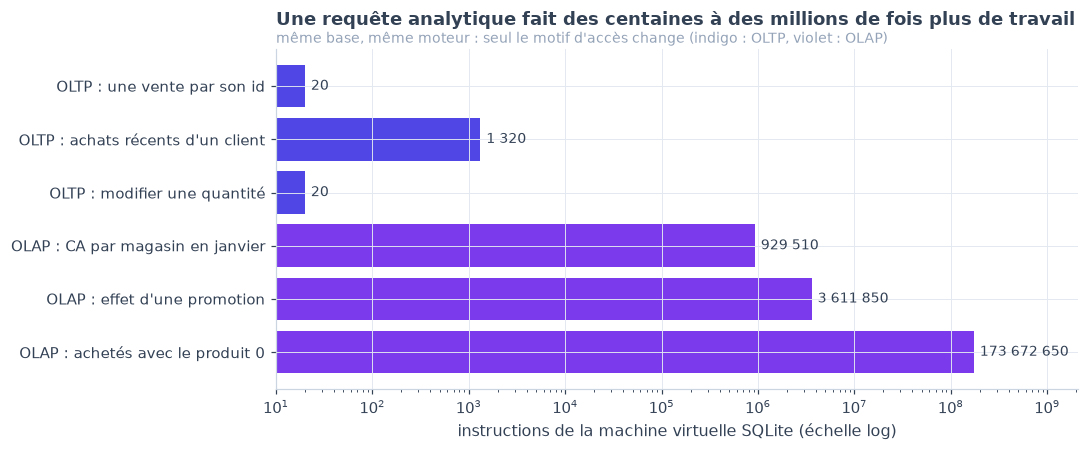

la plus légère des requêtes OLAP fait 704 fois plus de travail que la plus lourde des requêtes OLTP


In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [INDIGO if n.startswith("OLTP") else VIOLET for n in work.index]
bars = ax.barh(work.index[::-1], work["instructions VM"][::-1], color=colors[::-1])
ax.set_xscale("log")
for b, v in zip(bars, work["instructions VM"][::-1]):
    ax.text(v * 1.15, b.get_y() + b.get_height() / 2, fmt(v), va="center", fontsize=9)
ax.set_xlim(10, work["instructions VM"].max() * 12)
ax.set_xlabel("instructions de la machine virtuelle SQLite (échelle log)")
ax.set_title("Une requête analytique fait des centaines à des millions de fois plus de travail")
subtitle(ax, "même base, même moteur : seul le motif d'accès change (indigo : OLTP, violet : OLAP)")
plt.tight_layout(); plt.show()
ratio = work["instructions VM"].iloc[3:].min() / work["instructions VM"].iloc[:3].max()
print(f"la plus légère des requêtes OLAP fait {fmt(ratio)} fois plus de travail que la plus lourde des requêtes OLTP")

Les plans de requête expliquent l'écart : les requêtes OLTP **cherchent** (`SEARCH`)
directement les lignes voulues via la clé primaire ou l'index `sales_by_customer`, et
touchent quelques pages. Les requêtes OLAP **parcourent** (`SCAN`) toute la table, ou une
large plage de l'index par jour, et font de l'agrégation dans une structure temporaire.
Leur coût croît avec la taille de la table, celui des requêtes OLTP presque pas : c'est
ce que montre la mesure suivante, où l'on fait grossir la base.

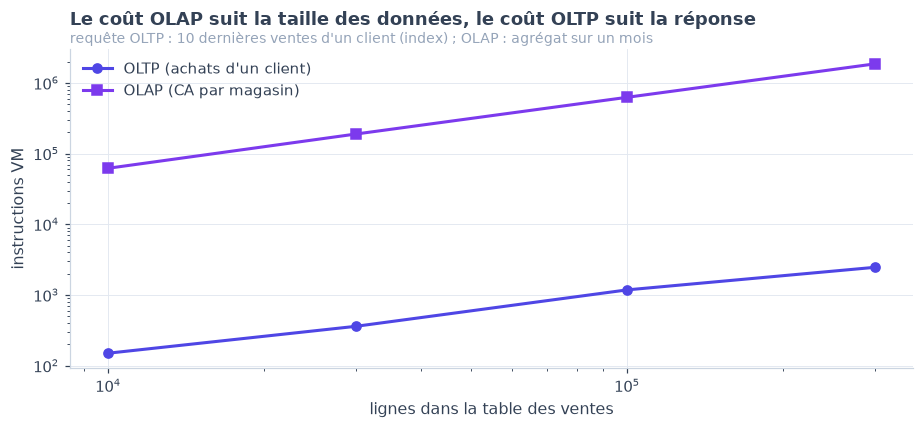

,OLTP (achats d'un client),OLAP (CA par magasin)
lignes,,
10000,150,62040
30000,360,189170
100000,1180,626090
300000,2460,1858510


In [7]:
sizes = [10_000, 30_000, 100_000, 300_000]
scale_rows = []
for n in sizes:
    c2 = sqlite3.connect(":memory:")
    ar.make_shop_db(c2, n_sales=n, seed=1)
    scale_rows.append({"lignes": n,
                       "OLTP (achats d'un client)": ar.vm_steps(c2, QUERIES["OLTP : achats récents d'un client"][0], (42,)),
                       "OLAP (CA par magasin)": ar.vm_steps(c2, QUERIES["OLAP : CA par magasin en janvier"][0])})
    c2.close()
scale = pd.DataFrame(scale_rows).set_index("lignes")

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.loglog(scale.index, scale.iloc[:, 0], "o-", color=INDIGO, label=scale.columns[0])
ax.loglog(scale.index, scale.iloc[:, 1], "s-", color=VIOLET, label=scale.columns[1])
ax.set_xlabel("lignes dans la table des ventes"); ax.set_ylabel("instructions VM")
ax.set_title("Le coût OLAP suit la taille des données, le coût OLTP suit la réponse")
subtitle(ax, "requête OLTP : 10 dernières ventes d'un client (index) ; OLAP : agrégat sur un mois")
ax.legend(); plt.tight_layout(); plt.show()
scale

Quand la table est multipliée par 30, le travail de la requête analytique l'est aussi
(pente 1 en échelle log-log), alors que celui de la requête ponctuelle ne fait que
suivre le nombre de ventes du client, qui grossit lui aussi un peu car notre base
ajoute des ventes sans ajouter de clients. Voici, reformulé et complété de nos mesures,
le contraste que dresse le tableau 1-1 du livre :

In [8]:
pd.DataFrame({
    "OLTP (opérationnel)": ["requêtes ponctuelles par clé", "créer, modifier, supprimer des lignes",
                            "utilisateur d'une appli web ou mobile", "vérifier qu'une action est autorisée",
                            "fixées par le code applicatif", "beaucoup de petites requêtes",
                            "l'état courant", "Go à To",
                            f"{fmt(work['instructions VM'].iloc[:3].mean())} instructions VM en moyenne"],
    "OLAP (analytique)": ["agrégats sur beaucoup de lignes", "import en masse (ETL) ou flux d'événements",
                          "analyste interne, aide à la décision", "détecter des fraudes, des abus",
                          "arbitraires, exploration ad hoc", "peu de requêtes, chacune complexe",
                          "l'historique des événements", "To à Po",
                          f"{fmt(work['instructions VM'].iloc[3:].mean())} instructions VM en moyenne"],
}, index=["lecture typique", "écriture typique", "utilisateur humain", "usage par une machine",
          "requêtes", "volume de requêtes", "les données représentent", "taille", "notre mesure"])

,OLTP (opérationnel),OLAP (analytique)
lecture typique,requêtes ponctuelles par clé,agrégats sur beaucoup de lignes
écriture typique,"créer, modifier, supprimer des lignes",import en masse (ETL) ou flux d'événements
utilisateur humain,utilisateur d'une appli web ou mobile,"analyste interne, aide à la décision"
usage par une machine,vérifier qu'une action est autorisée,"détecter des fraudes, des abus"
requêtes,fixées par le code applicatif,"arbitraires, exploration ad hoc"
volume de requêtes,beaucoup de petites requêtes,"peu de requêtes, chacune complexe"
les données représentent,l'état courant,l'historique des événements
taille,Go à To,To à Po
notre mesure,453 instructions VM en moyenne,59 404 670 instructions VM en moyenne


Deux nuances. D'abord, le « online » d'OLAP est ambigu : il signifie probablement que
l'analyste interroge le système **interactivement**, et pas seulement via des rapports
prédéfinis. Ensuite, la frontière n'est pas toujours nette : la requête « achetés avec le
produit 0 » est une auto-jointure qui pourrait aussi servir, précalculée, à afficher des
recommandations sur le site.

> **À retenir.** OLTP : beaucoup de petites requêtes ponctuelles, au coût indépendant de
> la taille des données. OLAP : peu de requêtes, chacune parcourant une grande partie des
> données, au coût proportionnel à leur volume. Ces deux motifs appellent des
> organisations physiques différentes (chapitre 4).

## 4. Pourquoi ne pas lancer l'analytique sur la base opérationnelle ? (section *Characterizing Transaction Processing and Analytics*)

Le livre donne deux raisons de ne pas laisser les utilisateurs écrire leurs propres
requêtes SQL sur une base OLTP : la **sécurité** (lire ou modifier des données
auxquelles ils n'ont pas droit) et la **performance** (une requête coûteuse ralentit
tout le monde). Quantifions la seconde.

**Modèle.** Une base OLTP dispose de $c = 8$ cœurs, avec une file d'attente commune. Elle
reçoit 4 000 requêtes par seconde de 1 ms en moyenne (durées exponentielles) : la charge
vaut $\rho = 4\,000 \times 0{,}001 / 8 = 0{,}5$, confortable. Un analyste lance des
requêtes qui occupent chacune un cœur pendant 15 s. Tant que $k$ requêtes analytiques
tournent, les requêtes OLTP n'ont plus que $8 - k$ cœurs et leur charge effective devient
$4 / (8 - k)$ : à $k = 4$, elle atteint 1 ; au-delà, la file **diverge** (il arrive plus
de travail qu'on ne peut en traiter). La formule M/M/c (`ar.mmc_response_time`) donne le
temps de réponse moyen en régime stationnaire ; la simulation (`ar.fifo_servers`) montre
la dynamique.

In [9]:
lam, mu, c = 4000.0, 1000.0, 8
ks = np.arange(0, 6)
theory = pd.DataFrame({"requêtes analytiques en cours": ks,
                       "cœurs libres pour l'OLTP": c - ks,
                       "charge OLTP effective": lam / mu / (c - ks),
                       "temps de réponse moyen (ms)": [ar.mmc_response_time(lam, mu, c - k) * 1e3 for k in ks]})
theory.set_index("requêtes analytiques en cours")

,cœurs libres pour l'OLTP,charge OLTP effective,temps de réponse moyen (ms)
requêtes analytiques en cours,,,
0,8,0.500,1.015
1,7,0.571,1.045
2,6,0.667,1.142
3,5,0.800,1.554
4,4,1.000,inf
5,3,1.333,inf


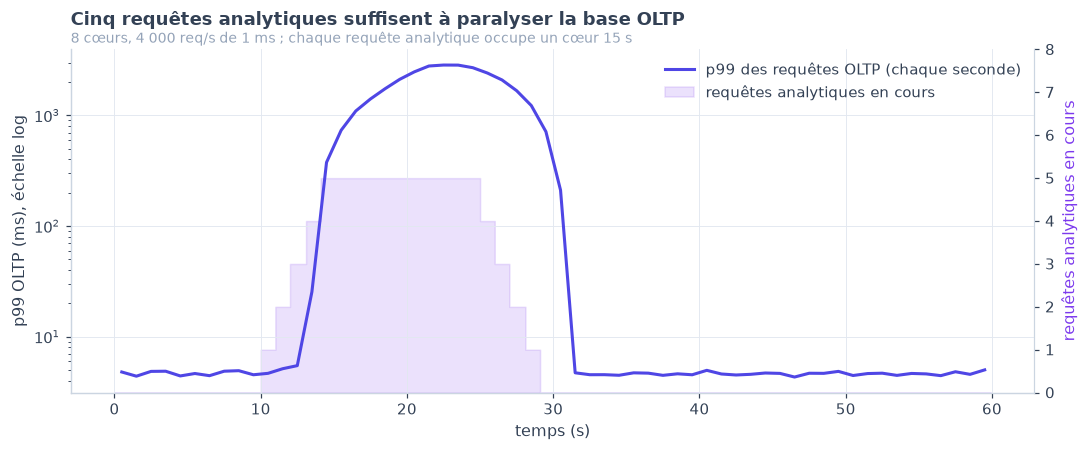

p99 OLTP avant 10 s : 4.7 ms ; pire seconde : 2.9 s ; fin des requêtes analytiques : 29 s ; retour sous 5 ms à t = 31 s


In [10]:
T = 60.0
arr = np.cumsum(rng.exponential(1 / lam, int(lam * T * 1.1)))
arr = arr[arr < T]
svc = rng.exponential(1 / mu, arr.size)
# cinq requêtes analytiques de 15 s, lancées à 10, 11, 12, 13 et 14 s
olap_t = np.array([10.0, 11.0, 12.0, 13.0, 14.0])
OLAP_D = 15.0
all_t = np.concatenate([arr, olap_t])
all_s = np.concatenate([svc, np.full(olap_t.size, OLAP_D)])
is_olap = np.concatenate([np.zeros(arr.size, bool), np.ones(olap_t.size, bool)])
order = np.argsort(all_t, kind="stable")
start, end = ar.fifo_servers(all_t[order], all_s[order], c=c)
st_all = np.empty_like(all_t); st_all[order] = start
resp = np.empty_like(all_t); resp[order] = end - all_t[order]
oltp_resp = resp[~is_olap]
olap_start = st_all[is_olap]

sec = np.floor(arr).astype(int)
p99 = pd.Series(oltp_resp * 1e3).groupby(sec).quantile(0.99)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.semilogy(p99.index + 0.5, p99.values, color=INDIGO, lw=2, label="p99 des requêtes OLTP (chaque seconde)")
ax.set_xlabel("temps (s)"); ax.set_ylabel("p99 OLTP (ms), échelle log")
ax2 = ax.twinx()
grid = np.arange(0, 60, 0.1)
running = [((olap_start <= g) & (olap_start + OLAP_D > g)).sum() for g in grid]
ax2.fill_between(grid, running, step="post", color=VIOLET, alpha=0.15, label="requêtes analytiques en cours")
ax2.set_ylim(0, 8); ax2.set_ylabel("requêtes analytiques en cours", color=VIOLET); ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.set_title("Cinq requêtes analytiques suffisent à paralyser la base OLTP")
subtitle(ax, "8 cœurs, 4 000 req/s de 1 ms ; chaque requête analytique occupe un cœur 15 s")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right"); plt.tight_layout(); plt.show()
calm = p99[(p99.index > 30) & (p99 < 5)].index.min()
print(f"p99 OLTP avant 10 s : {np.quantile(oltp_resp[arr < 10], 0.99) * 1e3:.1f} ms ; "
      f"pire seconde : {p99.max() / 1e3:.1f} s ; fin des requêtes analytiques : {(olap_start + OLAP_D).max():.0f} s ; "
      f"retour sous 5 ms à t = {calm} s")

Le p99 reste de l'ordre de quelques millisecondes tant qu'au plus trois requêtes
analytiques tournent (charge effective 0,8 au plus, conforme au tableau théorique). À la
quatrième, la charge atteint 1 ; à la cinquième, elle vaut 4/3 : il arrive 4 000
requêtes par seconde pour une capacité de 3 000, la file grossit de 1 000 requêtes à
chaque seconde et le p99 passe de quelques millisecondes à **près de trois secondes**. Pire,
la file accumulée ne se résorbe pas instantanément quand les requêtes analytiques se
terminent : il faut encore quelques secondes de rattrapage. Pendant ce temps, tous les
utilisateurs du site attendent. Un vrai moteur a d'autres mécanismes (priorités, limites
de ressources par requête, mais aussi verrous et cache de pages pollué par le parcours) ;
la conclusion reste : on isole l'analytique sur **un autre système**.

> **À retenir.** Une requête analytique monopolise des ressources pendant des secondes ou
> des minutes ; sur une base OLTP proche de sa capacité, quelques-unes suffisent à faire
> exploser la latence de tous les utilisateurs. C'est la raison d'être de l'entrepôt de
> données (cours 2).